## ⚙️ Load the GROMACS–PLUMED Environment

Loads the required **compiler, MPI, CUDA, GROMACS, and PLUMED environment** on ACCRE and makes the configured GROMACS–PLUMED installation available within the notebook for subsequent HREMD setup and simulations.

In [14]:
import os
import subprocess

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    # run in bash, capture environment
    result = subprocess.run(cmd, shell=True, executable="/bin/bash", capture_output=True, text=True)
    for line in result.stdout.splitlines():
        key, _, value = line.partition("=")
        os.environ[key] = value


In [ ]:
load_gmx_plumed()

# 1a 🌡️ Temperature Screening Protocol

To estimate an appropriate upper temperature before setting up **solute tempering / HREMD**, I ran short independent protein simulations across a temperature ladder.

## What I did

- Prepared simulations at **300, 400, 500, 600, 700, 800, 900, and 1000 K**
- Created separate folders under `Temp/T{T}`
- Edited `ref_t` in `grompp.mdp` for each temperature using automated folder-specific temperature assignment.
- Used `b4md.gro` and `topol.top` to generate each `.tpr` (refer to Gromacs_Solvated_MD_HPC repository to find out how to generate these files)
- Ran each temperature independently for **10ns**

✅ Goal: identify the lowest temperature showing barrier crossing and reversible sampling.

In [9]:
%%writefile run_temps.py

import os
import subprocess
import re
from contextlib import contextmanager

@contextmanager
def cd(newdir):
    prevdir = os.getcwd()
    os.chdir(newdir)
    try:
        yield
    finally:
        os.chdir(prevdir)

def sanitize_env_for_mpi():
    for k in list(os.environ.keys()):
        if k.startswith("BASH_FUNC_") or k in ("ml", "module", "which", "setup_accre_software_stack"):
            os.environ.pop(k, None)

def run_mpi(command):
    mpicmd = "mpirun"
    if "SLURM_JOB_ID" not in os.environ:
        mpicmd += " --oversubscribe"
    subprocess.run(f"{mpicmd} {command}", shell=True, check=True)

def load_gmx_plumed():
    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2
    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC
    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH
    env
    """
    result = subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True,
        check=True
    )

    for line in result.stdout.splitlines():
        if "=" in line:
            key, _, value = line.partition("=")
            os.environ[key] = value

workdir = os.getcwd()
print(f"📂 Using current directory: {workdir}")

print("🔄 Loading GROMACS + PLUMED environment...")
load_gmx_plumed()
sanitize_env_for_mpi()
print("✅ Environment ready.")

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

replica_dirs = []

for T in Ts:
    replica_dir = os.path.join("Temp", f"T{T}")
    os.makedirs(replica_dir, exist_ok=True)

    with open("grompp.mdp") as f_in, open(os.path.join(replica_dir, "grompp.mdp"), "w") as f_out:
        for line in f_in:
            raw = line.rstrip("\n")
            if re.match(r"^\s*ref[_-]t\s*=", raw):
                base, *comment = raw.split(";", 1)
                indent = re.match(r"^\s*", base).group(0)
                raw = f"{indent}ref_t                   = {T}     {T}"
                if comment:
                    raw += " ;" + comment[0]
            print(raw, file=f_out)

    with cd(replica_dir):
        run_mpi("-np 1 gmx_mpi grompp -f grompp.mdp -c ../../b4md.gro -p ../../protein.top")
        replica_dirs.append(os.path.abspath(os.getcwd()))

for d in replica_dirs:
    print(f"▶️ Running mdrun in {d} ...")
    with cd(d):
        run_mpi("-np 1 gmx_mpi mdrun -nsteps 5000000 -pin on -ntomp 12")

Overwriting run_temps.py


Run the python script 

In [ ]:
!python run_temps.py

📂 Using current directory: /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
🔄 Loading GROMACS + PLUMED environment...
✅ Environment ready.
               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/Temp/T300
Command line:
  gmx_mpi grompp -f grompp.mdp -c ../../b4md.gro -p ../../protein.top

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Setting the LD random seed to -33736897

Generated 2145 of the 2145 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded ne

Optional: PyMOL Visualization 🎬

Generate multi-frame PDB files from trajectories for visualization in **PyMOL**.

✨ Frames were centered, PBC corrected, and written every 50 frames to compare temperature-dependent conformational changes.

In [ ]:
import os
import subprocess

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

procs = []

for T in Ts:
    d = os.path.join("Temp", f"T{T}")

    cmd = (
        f"cd {d} && "
        f"echo 1 1 | gmx_mpi trjconv "
        f"-f traj_comp.xtc "
        f"-s topol.tpr "
        f"-center "
        f"-pbc mol "
        f"-skip 50 "
        f"-o T{T}_movie_skip50.pdb "
        f"> trjconv_movie.log 2>&1"
    )

    print(f"▶️ Launching T{T}")
    p = subprocess.Popen(cmd, shell=True)
    procs.append((T, d, p))

failed = []

for T, d, p in procs:
    ret = p.wait()

    if ret == 0:
        print(f"✅ Finished T{T}: {d}/T{T}_movie_skip50.pdb")
    else:
        print(f"❌ Failed T{T}. Check {d}/trjconv_movie.log")
        failed.append(T)

if failed:
    print("Failed temperatures:", failed)
else:
    print("🎉 All multi-frame PDB files created.")

In [ ]:
import os
import subprocess

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

procs = []

for T in Ts:
    d = os.path.join("Temp", f"T{T}")

    cmd = (
        f"cd {d} && "
        f"echo 1 1 | gmx_mpi trjconv "
        f"-f traj_comp.xtc "
        f"-s topol.tpr "
        f"-center "
        f"-pbc mol "
        f"-skip 50 "
        f"-o T{T}_movie_skip50.pdb "
        f"> trjconv_movie.log 2>&1"
    )

    print(f"▶️ Launching T{T}")
    p = subprocess.Popen(cmd, shell=True)
    procs.append((T, d, p))

failed = []

for T, d, p in procs:
    ret = p.wait()

    if ret == 0:
        print(f"✅ Finished T{T}: {d}/T{T}_movie_skip50.pdb")
    else:
        print(f"❌ Failed T{T}. Check {d}/trjconv_movie.log")
        failed.append(T)

if failed:
    print("Failed temperatures:", failed)
else:
    print("🎉 All multi-frame PDB files created.")

▶️ Launching T300
▶️ Launching T400
▶️ Launching T500
▶️ Launching T600
▶️ Launching T700
▶️ Launching T800
▶️ Launching T900
▶️ Launching T1000


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

✅ Finished T300: Temp/T300/T300_movie_skip50.pdb
✅ Finished T400: Temp/T400/T400_movie_skip50.pdb
✅ Finished T500: Temp/T500/T500_movie_skip50.pdb
✅ Finished T600: Temp/T600/T600_movie_skip50.pdb
✅ Finished T700: Temp/T700/T700_movie_skip50.pdb
✅ Finished T800: Temp/T800/T800_movie_skip50.pdb
✅ Finished T900: Temp/T900/T900_movie_skip50.pdb
✅ Finished T1000: Temp/T1000/T1000_movie_skip50.pdb
🎉 All multi-frame PDB files created.


## Analysis 📊

For each temperature simulation:

- Centered and unwrapped protein trajectories (`trjconv`)
- Calculated **radius of gyration (Rg)** (`gyrate`)
- Calculated **protein RMSD** relative to the starting structure (`rms`)

✨ Rg and RMSD trends were used to assess temperature-dependent conformational changes and identify temperatures capable of overcoming structural barriers.

Note this runs calculations in parallel make sure that you have enough cores

In [ ]:
import os
import subprocess

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

for T in Ts:

    replica_dir = f"Temp/T{T}"

    tpr = f"{replica_dir}/topol.tpr"
    xtc = f"{replica_dir}/traj_comp.xtc"

    centered_xtc = f"{replica_dir}/centered_protein.xtc"
    gyrate_xvg = f"{replica_dir}/gyration.xvg"
    rmsd_xvg = f"{replica_dir}/rmsd.xvg"

    if not os.path.exists(tpr):
        print(f"❌ Missing: {tpr}")
        continue

    if not os.path.exists(xtc):
        print(f"❌ Missing: {xtc}")
        continue

    print(f"▶️ Processing T{T}")

    # Center protein and output protein-only trajectory
    subprocess.run(
        f'printf "1\n1\n" | gmx_mpi trjconv -f {xtc} -s {tpr} -o {centered_xtc} -center -pbc nojump',
        shell=True,
        check=True
    )

    # Radius of gyration for Protein
    subprocess.run(
        f'printf "1\n" | gmx_mpi gyrate -f {centered_xtc} -s {tpr} -o {gyrate_xvg}',
        shell=True,
        check=True
    )

    # RMSD for Protein fitted to Protein
    subprocess.run(
        f'printf "1\n1\n" | gmx_mpi rms -f {centered_xtc} -s {tpr} -o {rmsd_xvg}',
        shell=True,
        check=True
    )

    print(f"✅ Finished T{T}")

print("🎉 Finished centered trajectory, Rg, and RMSD analysis.")

▶️ Processing T300


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Note that major changes are planned in future for trjconv, to improve usability and utility.
Select group for centering
Selected 1: 'Protein'
Select group for output
Selected 1: 'Protein'


               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi gyrate -f Temp/T300/centered_protein.xtc -s Temp/T300/topol.tpr -o Temp/T300/gyration.xvg

Reading file Temp/T300/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file Temp/T300/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 42071 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (    MainChain+H) has  1348 elements
Group     8 (      SideChain) has  3074 elements
Group     9 (

Selected 1: 'Protein'


...

               :-) GROMACS - gmx gyrate, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi gyrate -f Temp/T1000/centered_protein.xtc -s Temp/T1000/topol.tpr -o Temp/T1000/gyration.xvg

Reading file Temp/T1000/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Reading file Temp/T1000/topol.tpr, VERSION 2023.5-plumed_2.9.2 (single precision)
Group     0 (         System) has 42071 elements
Group     1 (        Protein) has  4422 elements
Group     2 (      Protein-H) has  2178 elements
Group     3 (        C-alpha) has   271 elements
Group     4 (       Backbone) has   813 elements
Group     5 (      MainChain) has  1085 elements
Group     6 (   MainChain+Cb) has  1345 elements
Group     7 (    MainChain+H) has  1348 elements
Group     8 (      SideChain) has  3074 elements
Group   

Selected 1: 'Protein'


/bin/sh: ml: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `ml'
/bin/sh: find_port: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `find_port'
/bin/sh: which: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `which'
/bin/sh: create_passwd: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `create_passwd'
/bin/sh: random_number: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `random_number'
/bin/sh: module: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `module'
/bin/sh: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/sh: error importing function definition for `setup_accre_software_stack'
/bin/sh: wait_until_port_used: line 1: syntax error: unexpected end of file
/bin/sh: error impor

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T1000
🎉 Finished centered trajectory, Rg, and RMSD analysis.


Last frame       2000 time 10000.000   

Back Off! I just backed up Temp/T1000/rmsd.xvg to Temp/T1000/#rmsd.xvg.1#

GROMACS reminds you: "If all else fails, immortality can always be assured by spectacular error." (John Kenneth Galbraith)



Plots to Analyze the RMSD and Rg across all temperatures analyzed

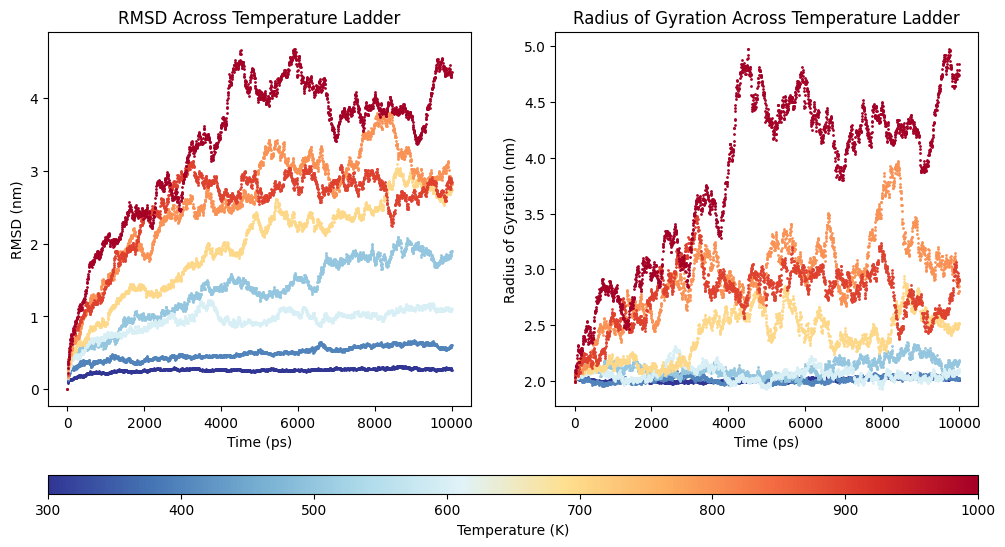

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# ===================== COLORS ============================
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# ===================== TEMPERATURES ======================
# =========================================================

Ts = [300, 400, 500, 600, 700, 800, 900, 1000]

norm = Normalize(vmin=min(Ts), vmax=max(Ts))

# =========================================================
# ===================== XVG READER ========================
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# ===================== LOAD DATA =========================
# =========================================================

rmsd_data = []
rg_data = []

for T in Ts:

    rmsd_file = f"Temp/T{T}/rmsd.xvg"
    rg_file   = f"Temp/T{T}/gyration.xvg"

    rmsd_data.append(read_xvg(rmsd_file))
    rg_data.append(read_xvg(rg_file))

# =========================================================
# ===================== FIGURE ============================
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])

cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# ===================== RMSD ==============================
# =========================================================

for i, T in enumerate(Ts):

    color = CMAP(norm(T))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Temperature Ladder")

# =========================================================
# ===================== Rg ================================
# =========================================================

for i, T in enumerate(Ts):

    color = CMAP(norm(T))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Temperature Ladder")

# =========================================================
# ===================== COLORBAR ==========================
# =========================================================

sm = ScalarMappable(
    norm=norm,
    cmap=CMAP
)

sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Temperature (K)")

# =========================================================
# ===================== OUTPUT ============================
# =========================================================

plt.show()

Inference 🔍

Lower temperatures (**300–500 K**) largely remained within the starting basin, whereas transitions toward ~**1.5 nm RMSD** emerged near **700 K**, consistent with the partially unfolded intermediate previously identified from SMOG simulations.

✨ As these simulations were only **10 ns**, the next step is to perform longer simulations (**~100 ns**) while narrowing the temperature range below **700 K** to better identify the onset of intermediate-state.

*************************************

## 1b🌡️ Narrowing Temperature Screening

Based on the initial temperature ladder, a second round of simulations was performed to refine the transition region associated with intermediate-state formation.

### Protocol

- Selected a narrower temperature range of **310–530 K** in **10 K increments**
- This range was chosen **arbitrarily below 700 K** following the initial screening results
- Generated independent temperature directories under `1b/T{T}`
- Modified `ref_t` in `grompp.mdp` for each temperature
- Generated temperature-specific `.tpr` files using `b4md.gro` and `topol.top`

✨ The goal was to more precisely identify conditions associated with intermediate-state sampling.

In [ ]:
import os
import subprocess
import re
from contextlib import contextmanager

@contextmanager
def cd(newdir):
    prevdir = os.getcwd()
    os.chdir(newdir)
    try:
        yield
    finally:
        os.chdir(prevdir)

def sanitize_env_for_mpi():
    for k in list(os.environ.keys()):
        if k.startswith("BASH_FUNC_") or k in (
            "ml",
            "module",
            "which",
            "setup_accre_software_stack"
        ):
            os.environ.pop(k, None)

def run_mpi(command):

    mpicmd = "mpirun"

    if "SLURM_JOB_ID" not in os.environ:
        mpicmd += " --oversubscribe"

    full_cmd = f"{mpicmd} {command}"

    subprocess.run(
        full_cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def load_gmx_plumed():

    cmd = """
    module load StdEnvACCRE/2023
    module load gcc/12.3
    module load openmpi/4.1.5
    module load cuda/12.2

    source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC

    export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
    export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
    export PATH=$HOME/plumed-2.9.2/bin:$PATH

    env
    """

    result = subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        capture_output=True,
        text=True,
        check=True
    )

    for line in result.stdout.splitlines():
        if "=" in line:
            key, _, value = line.partition("=")
            os.environ[key] = value

workdir = os.getcwd()

load_gmx_plumed()
sanitize_env_for_mpi()

Ts = list(range(310, 531, 10))

input_gro = os.path.join(workdir, "b4md.gro")
input_top = os.path.join(workdir, "topol.top")
input_mdp = os.path.join(workdir, "grompp.mdp")

main_replica_dir = os.path.join(workdir, "1b")
os.makedirs(main_replica_dir, exist_ok=True)

for T in Ts:

    replica_dir = os.path.join(main_replica_dir, f"T{T}")
    os.makedirs(replica_dir, exist_ok=True)

    output_mdp = os.path.join(replica_dir, "grompp.mdp")

    with open(input_mdp) as f_in, open(output_mdp, "w") as f_out:

        for line in f_in:

            raw = line.rstrip("\n")

            if re.match(r"^\s*ref[_-]t\s*=", raw):

                base, *comment = raw.split(";", 1)

                indent = re.match(r"^\s*", base).group(0)

                raw = f"{indent}ref_t                   = {T}     {T}"

                if comment:
                    raw += " ;" + comment[0]

            print(raw, file=f_out)

    with cd(replica_dir):

        run_mpi(
            f"-np 1 gmx_mpi grompp "
            f"-f grompp.mdp "
            f"-c {input_gro} "
            f"-p {input_top} "
            f"-o md.tpr"
        )

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T380
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5


Setting the LD random seed to -268705923

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 380 K

Calculated rlist for 1x1 atom pair-list as 0.943 nm, buffer size 0.043 nm

Set rlist, assuming 4x4 atom pair-list, to 0.902 nm, buffer size 0.002 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Wicky-wicky Wa-wild West" (Will Smith)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T390
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance

Setting the LD random seed to 1859902968

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 390 K

Calculated rlist for 1x1 atom pair-list as 0.944 nm, buffer size 0.044 nm

Set rlist, assuming 4x4 atom pair-list, to 0.903 nm, buffer size 0.003 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "Can I have everything louder than everything else?" (Deep Purple)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T400
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also hav

...

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs



Calculated rlist for 1x1 atom pair-list as 0.956 nm, buffer size 0.056 nm

Set rlist, assuming 4x4 atom pair-list, to 0.910 nm, buffer size 0.010 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dimensions for X Y Z
Using a fourier grid of 60x72x64, spacing 0.112 0.117 0.116

Estimate for the relative computational load of the PME mesh part: 0.30



GROMACS reminds you: "Same sex marriage is not a gay privilege, it's equal rights. Privilege would be something like gay people not paying taxes. Like churches don't." (Ricky Gervais)

               :-) GROMACS - gmx grompp, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T530
Command line:
  gmx_mpi grompp -f grompp.mdp -c /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/b4md.gro -p /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/topol.top -o md.tpr

Ignoring obsolete mdp entry 'title'
Ignoring obsolete mdp entry 'ns_type'

NOTE 1 [file grompp.mdp]:
  You have set rlist larger than the interaction cut-off, but you also have
  verlet-buffer-tolerance > 0. Will set rlist using
  verlet-buffer-tolerance.

Generating 1-4 interactions: fudge = 0.5


Setting the LD random seed to 1271487999

Generated 2145 of the 2145 non-bonded parameter combinations

Generated 2145 of the 2145 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

turning H bonds into constraints...

Excluding 2 bonded neighbours molecule type 'SOL'

turning H bonds into constraints...

Excluding 1 bonded neighbours molecule type 'NA'

turning H bonds into constraints...
Analysing residue names:
There are:   271    Protein residues
There are: 12548      Water residues
There are:     5        Ion residues
Analysing Protein...

The largest distance between excluded atoms is 0.424 nm between atom 3758 and 3765

Determining Verlet buffer for a tolerance of 0.005 kJ/mol/ps at 530 K

Calculated rlist for 1x1 atom pair-list as 0.957 nm, buffer size 0.057 nm

Set rlist, assuming 4x4 atom pair-list, to 0.911 nm, buffer size 0.011 nm

Note that mdrun will redetermine rlist based on the actual pair-list setup
Calculating fourier grid dime

Number of degrees of freedom in T-Coupling group Protein is 11021.62
Number of degrees of freedom in T-Coupling group non-Protein is 75300.38

NOTE 2 [file grompp.mdp]:
  This run will generate roughly 4056 Mb of data


There were 2 NOTEs

GROMACS reminds you: "I'm not interrupting you, I'm putting our conversation in full-duplex mode." (Antone Roundy)



You can either run on jupyternotebook (use A6000 with 4 GPUs) itself or submit slurm script 

In [ ]:
import subprocess

slurm_script = """#!/bin/bash
#SBATCH --job-name=6ONI_TempTest
#SBATCH --mail-user=mithun.nag.karadi.giridhar@vanderbilt.edu
#SBATCH --mail-type=ALL
#SBATCH --nodes=1
#SBATCH --ntasks=16
#SBATCH --cpus-per-task=1
#SBATCH --mem=60G
#SBATCH --time=2-00:00:00
#SBATCH --gres=gpu:nvidia_rtx_a6000:4
#SBATCH --partition=batch_gpu
#SBATCH --account=csb_gpu_acc

#SBATCH --output=6ONI_TempTest_out_%j.log
#SBATCH --error=6ONI_TempTest_err_%j.log

module load StdEnvACCRE/2023
module load gcc/12.3
module load openmpi/4.1.5
module load cuda/12.2

source $HOME/gromacs-2023.5-plumed-mpi/bin/GMXRC

export PLUMED_KERNEL=$HOME/plumed-2.9.2/lib/libplumedKernel.so
export LD_LIBRARY_PATH=$HOME/plumed-2.9.2/lib:$LD_LIBRARY_PATH
export PATH=$HOME/plumed-2.9.2/bin:$PATH

mpirun gmx_mpi mdrun \
-multidir T310 T320 T330 T340 T350 T360 T370 T380 T390 T400 T410 T420 T430 T440 T450 T460 T470 T480 T490 T500 T510 T520 T530 \
-deffnm md \
-nsteps 50000000 \
-nb gpu \
-pme gpu \
-bonded gpu \
-gputasks 00000011111122222233333 \
-pin auto \
-ntomp 1
"""

with open("1b/run_temp_test.slurm", "w") as f:
    f.write(slurm_script)

subprocess.run(
    "cd 1b && sbatch run_temp_test.slurm",
    shell=True,
    check=True
)

Submitted batch job 10853718


CompletedProcess(args='cd 1b && sbatch run_temp_test.slurm', returncode=0)

# 🚀 Parallel RMSD + Rg Analysis

### 🎯 Goal
Run all temperature replicas (**T310 → T530**) in parallel for faster analysis.

### ⚡ Calculates

✅ RMSD (`gmx rms`)  
✅ Radius of Gyration (`gmx gyrate`)  

### 📂 Inputs

```
topol.tpr
traj_comp.xtc
```

### 📤 Outputs

```
rmsd.xvg
gyration.xvg
```

### 🔥 Parallel execution

```python
max_workers = len(Ts)
```

Runs all temperatures simultaneously instead of one-by-one.

In [ ]:
import os
import subprocess
from concurrent.futures import ThreadPoolExecutor, as_completed

def run_cmd(cmd):
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def analyze_temperature(T):

    replica_dir = os.path.join(main_dir, f"T{T}")

    tpr = os.path.join(replica_dir, "md.tpr")
    xtc = os.path.join(replica_dir, "md.xtc")

    gyrate_xvg = os.path.join(replica_dir, "gyration.xvg")
    rmsd_xvg = os.path.join(replica_dir, "rmsd.xvg")

    if not os.path.exists(tpr):
        return f"❌ T{T}: missing topol.tpr"

    if not os.path.exists(xtc):
        return f"❌ T{T}: missing traj_comp.xtc"

    print(f"▶️ Starting T{T}", flush=True)

    # Run Rg and RMSD sequentially inside each temperature
    run_cmd(
        f'printf "1\\n" | '
        f'gmx_mpi gyrate '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{gyrate_xvg}"'
    )

    run_cmd(
        f'printf "1\\n1\\n" | '
        f'gmx_mpi rms '
        f'-f "{xtc}" '
        f'-s "{tpr}" '
        f'-o "{rmsd_xvg}"'
    )

    return f"✅ Finished T{T}"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "1b")

Ts = list(range(310, 531, 10))

# This runs all temperatures at once
max_workers = len(Ts)

# ============================================================
# Run all temperatures in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(analyze_temperature, T)
        for T in Ts
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished all parallel Rg and RMSD analysis.")

▶️ Starting T390▶️ Starting T410
▶️ Starting T420
▶️ Starting T510
▶️ Starting T430
▶️ Starting T480
▶️ Starting T500
▶️ Starting T450
▶️ Starting T470
▶️ Starting T530
▶️ Starting T380
▶️ Starting T490

▶️ Starting T520
▶️ Starting T440
▶️ Starting T400
▶️ Starting T460


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

▶️ Starting T350
▶️ Starting T360
▶️ Starting T310
▶️ Starting T330
▶️ Starting T340
▶️ Starting T320
▶️ Starting T370


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en

Selected 1: 'Protein'


...

Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T340
Selected 1: 'Protein'
Selected 1: 'Protein'




GROMACS reminds you: "It takes money to make money, they say" (Lou Reed)



✅ Finished T330
Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T320




GROMACS reminds you: "It takes money to make money, they say" (Lou Reed)

Last frame      40000 time 200000.000   

GROMACS reminds you: "People disagree with me. I just ignore them." (Linus Torvalds on the use of C++ in the kernel)



Selected 1: 'Protein'
Selected 1: 'Protein'
✅ Finished T370

🎉 Finished all parallel Rg and RMSD analysis.


The Script below just plots RMSD and Rg that this previous cell output

Valid temperatures: [310, 320, 330, 340, 350, 360, 370, 380, 390, 400, 410, 420, 430, 440, 450, 460, 470, 480, 490, 500, 510, 520, 530]


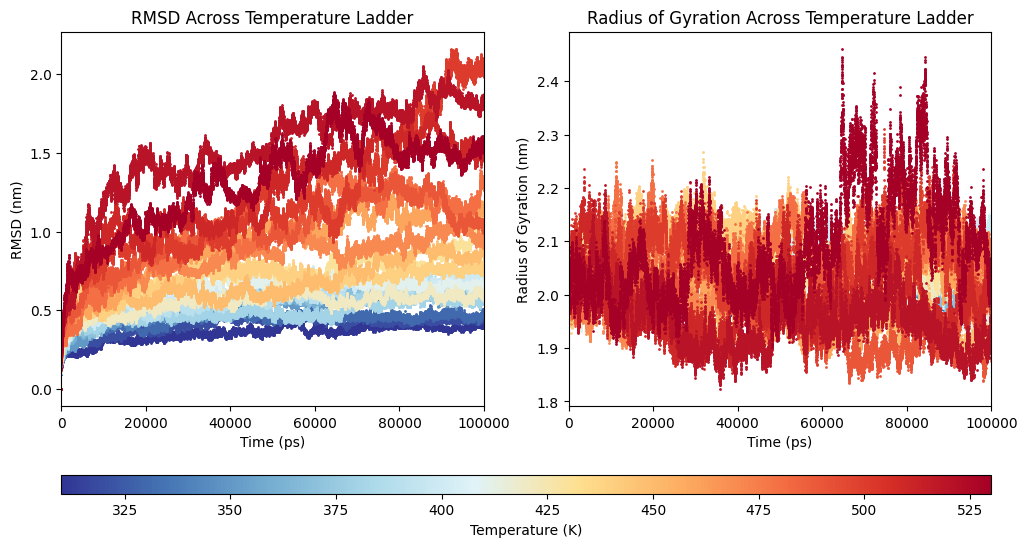

In [ ]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# =========================================================
# COLORS
# =========================================================

BASE_COLORS = [
    "#313695", "#4575b4", "#74add1", "#abd9e9", "#e0f3f8",
    "#fee090", "#fdae61", "#f46d43", "#d73027", "#a50026"
]

CMAP = LinearSegmentedColormap.from_list("seq", BASE_COLORS, 256)

# =========================================================
# TEMPERATURES
# =========================================================

Ts = list(range(310, 531, 10))
norm = Normalize(vmin=min(Ts), vmax=max(Ts))

main_dir = "1b"

# =========================================================
# XVG READER
# =========================================================

def read_xvg(filename):

    data = []

    with open(filename) as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            if line.startswith("@") or line.startswith("#"):
                continue

            try:
                data.append([float(x) for x in line.split()])
            except ValueError:
                continue

    return pd.DataFrame(data)

# =========================================================
# LOAD DATA
# =========================================================

rmsd_data = []
rg_data = []
valid_Ts = []

for T in Ts:

    rmsd_file = os.path.join(main_dir, f"T{T}", "rmsd.xvg")
    rg_file   = os.path.join(main_dir, f"T{T}", "gyration.xvg")

    if not os.path.exists(rmsd_file):
        print(f"❌ Missing: {rmsd_file}")
        continue

    if not os.path.exists(rg_file):
        print(f"❌ Missing: {rg_file}")
        continue

    rmsd_df = read_xvg(rmsd_file)
    rg_df = read_xvg(rg_file)

    if rmsd_df.empty or rg_df.empty:
        print(f"⚠️ Empty XVG for T{T}")
        continue

    rmsd_data.append(rmsd_df)
    rg_data.append(rg_df)
    valid_Ts.append(T)

print("Valid temperatures:", valid_Ts)

# =========================================================
# FIGURE
# =========================================================

fig = plt.figure(figsize=(12, 6))

gs = GridSpec(
    2,
    2,
    height_ratios=[1, 0.05],
    hspace=0.35
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cbar_ax = fig.add_subplot(gs[1, :])

# =========================================================
# RMSD
# =========================================================

for i, T in enumerate(valid_Ts):

    color = CMAP(norm(T))

    ax1.plot(
        rmsd_data[i][0],
        rmsd_data[i][1],
        ".",
        color=color,
        markersize=2,
        label=f"{T} K"
    )

ax1.set_xlabel("Time (ps)")
ax1.set_ylabel("RMSD (nm)")
ax1.set_title("RMSD Across Temperature Ladder")
ax1.set_xlim(0, 100000)

# =========================================================
# Rg
# =========================================================

for i, T in enumerate(valid_Ts):

    color = CMAP(norm(T))

    ax2.plot(
        rg_data[i][0],
        rg_data[i][1],
        ".",
        color=color,
        markersize=2,
        label=f"{T} K"
    )

ax2.set_xlabel("Time (ps)")
ax2.set_ylabel("Radius of Gyration (nm)")
ax2.set_title("Radius of Gyration Across Temperature Ladder")
ax2.set_xlim(0, 100000)

# =========================================================
# COLORBAR
# =========================================================

sm = ScalarMappable(norm=norm, cmap=CMAP)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal"
)

cbar.set_label("Temperature (K)")

# =========================================================
# OUTPUT
# =========================================================

plt.show()

## Potential Energy Extraction ⚡

Potential energy was extracted from `ener.edr` files across all temperature replicas (**310–530 K**) using `gmx energy`.

- Generated `potential.xvg` for each temperature
- Processing performed in parallel across replicas

✨ Potential energy trends were used to compare thermodynamic behavior across the temperature ladder.

In [ ]:
import os
import subprocess
import numpy as np
from concurrent.futures import ThreadPoolExecutor, as_completed

# ============================================================
# Parallel Potential Energy Extraction
#   Input:  1b/TXXX/ener.edr
#   Output: 1b/TXXX/potential.xvg
# ============================================================

def run_cmd(cmd):
    subprocess.run(
        cmd,
        shell=True,
        executable="/bin/bash",
        check=True
    )

def extract_potential(T):

    replica_dir = os.path.join(main_dir, f"T{T}")

    edr_file = os.path.join(replica_dir, "md.edr")
    out_xvg  = os.path.join(replica_dir, "potential.xvg")

    if not os.path.exists(edr_file):
        return f"❌ T{T}: missing ener.edr"

    print(f"▶️ Starting T{T}", flush=True)

    cmd = (
        f'echo "Potential" | '
        f'gmx_mpi energy '
        f'-f "{edr_file}" '
        f'-o "{out_xvg}" '
        f'-xvg none'
    )

    run_cmd(cmd)

    data = np.loadtxt(out_xvg)

    if data.ndim == 1:
        n_frames = 1
    else:
        n_frames = data.shape[0]

    return f"✅ T{T}: potential.xvg written, {n_frames} frames"

# ============================================================
# Settings
# ============================================================

workdir = os.getcwd()
main_dir = os.path.join(workdir, "1b")

Ts = list(range(310, 531, 10))

# Run all temperatures at once
max_workers = len(Ts)

# ============================================================
# Run in parallel
# ============================================================

with ThreadPoolExecutor(max_workers=max_workers) as executor:

    futures = [
        executor.submit(extract_potential, T)
        for T in Ts
    ]

    for future in as_completed(futures):
        try:
            print(future.result(), flush=True)
        except Exception as e:
            print(f"❌ Error: {e}", flush=True)

print("\n🎉 Finished extracting potential energy for all replicas.")

▶️ Starting T390
▶️ Starting T310
▶️ Starting T400
▶️ Starting T380
▶️ Starting T330
▶️ Starting T320
▶️ Starting T360
▶️ Starting T340
▶️ Starting T370
▶️ Starting T420
▶️ Starting T350
▶️ Starting T410
▶️ Starting T430
▶️ Starting T450
▶️ Starting T480
▶️ Starting T470
▶️ Starting T440
▶️ Starting T460
▶️ Starting T490
▶️ Starting T500
▶️ Starting T510
▶️ Starting T520
▶️ Starting T530


/bin/bash: ml: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `ml'
/bin/bash: find_port: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `find_port'
/bin/bash: which: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `which'
/bin/bash: create_passwd: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `create_passwd'
/bin/bash: random_number: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `random_number'
/bin/bash: module: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `module'
/bin/bash: setup_accre_software_stack: line 1: syntax error: unexpected end of file
/bin/bash: error importing function definition for `setup_accre_software_stack'
/bin/bash: wait_until_port_used: line 1: syntax error: unexpected en


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -441394         19    1062.18    14.3908  (kJ/mol)
✅ T490: potential.xvg written, 10001 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -476727         29    947.591   -172.986  (kJ/mol)
✅ T410: potential.xvg written, 10001 frames


Reading energy frame   8000 time 80000.000                        :-) GROMACS - gmx energy, 2023.5-plumed_2.9.2 (-:

Executable:   /home/karadim/gromacs-2023.5-plumed-mpi/bin/gmx_mpi
Data prefix:  /home/karadim/gromacs-2023.5-plumed-mpi
Working dir:  /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI
Command line:
  gmx_mpi energy -f /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T340/md.edr -o /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T340/potential.xvg -xvg none

Reading energy frame   9000 time 90000.000         Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T340/md.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
  1  Bond             2  Angle            3 


Statistics over 82375001 steps [ 0.0000 through 164750.0000 ps ], 1 data sets
All statistics are over 823751 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -525031         33    814.772   -219.237  (kJ/mol)
✅ T320: potential.xvg written, 16476 frames


...


Statistics over 81895001 steps [ 0.0000 through 163790.0000 ps ], 1 data sets
All statistics are over 818951 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -513297         37    847.155   -223.158  (kJ/mol)
✅ T340: potential.xvg written, 16380 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -472080         30     962.12   -214.212  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-----------------------------------------------------------------------------

Reading energy frame     50 time  500.000         Opened /panfs/accrepfs.vampire/data/kojetin_lab/HREMD_Preliminary_data/6ONI/1b/T450/md.edr as single precision energy file

Select the terms you want from the following list by
selecting either (part of) the name or the number or a combination.
End your selection with an empty line or a zero.
-------------------------------------------------------------------
Reading energy frame     60 time  600.000           1  Bond             2  Angle            3  Proper-Dih.      4  Per.-Imp.-Dih.
  5  LJ-14            6  Coulomb-14       7  LJ-(SR)          8  Disper.-corr. 
  9  Coulomb-(SR)    10  Coul.-recip.    11  Potential       12  Kinetic-En.   
 13  Total-Energy    14  Conserved-En.   15  Temperature     16  Pres.-DC      
 17  Pressure        18  Constr.-rmsd    19  Vir-XX          20  Vir-XY        
Reading energy frame   2000 time 20000.000          24  Vir-YZ        
 25  Vir-ZX          26  Vir-ZY          27  Vir-ZZ          28  Pr


Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -454005         15    1022.45    -96.054  (kJ/mol)

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -429460         19    1104.41    23.5922  (kJ/mol)
✅ T390: potential.xvg written, 10001 frames

Statistics over 50000001 steps [ 0.0000 through 100000.0000 ps ], 1 data sets
All statistics are over 500001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-----------------------------------------------------------------------------

Reading energy frame   1800 time 18000.000         
GROMACS reminds you: "Please implement proper hep writing" (GROMACS)

Last energy frame read 15963 time 159630.000         
Reading energy frame    900 time 9000.000          
GROMACS reminds you: "Please implement proper hep writing" (GROMACS)

Last energy frame read 10000 time 100000.000         
Reading energy frame   4000 time 40000.000         
GROMACS reminds you: "Please implement proper hep writing" (GROMACS)

Last energy frame read 10000 time 100000.000         
Reading energy frame  16000 time 160000.000         
GROMACS reminds you: "Please implement proper hep writing" (GROMACS)

Last energy frame read 10000 time 100000.000         

GROMACS reminds you: "Please implement proper hep writing" (GROMACS)

Last energy frame read 20000 time 200000.000         

GROMACS reminds you: "Please implement proper hep writing" (GROMACS)




Statistics over 100000001 steps [ 0.0000 through 200000.0000 ps ], 1 data sets
All statistics are over 1000001 points

Energy                      Average   Err.Est.       RMSD  Tot-Drift
-------------------------------------------------------------------------------
Potential                   -496862         31     885.85    -195.08  (kJ/mol)
✅ T440: potential.xvg written, 10001 frames
✅ T470: potential.xvg written, 10001 frames
✅ T350: potential.xvg written, 15964 frames
✅ T380: potential.xvg written, 10001 frames
✅ T370: potential.xvg written, 20001 frames

🎉 Finished extracting potential energy for all replicas.


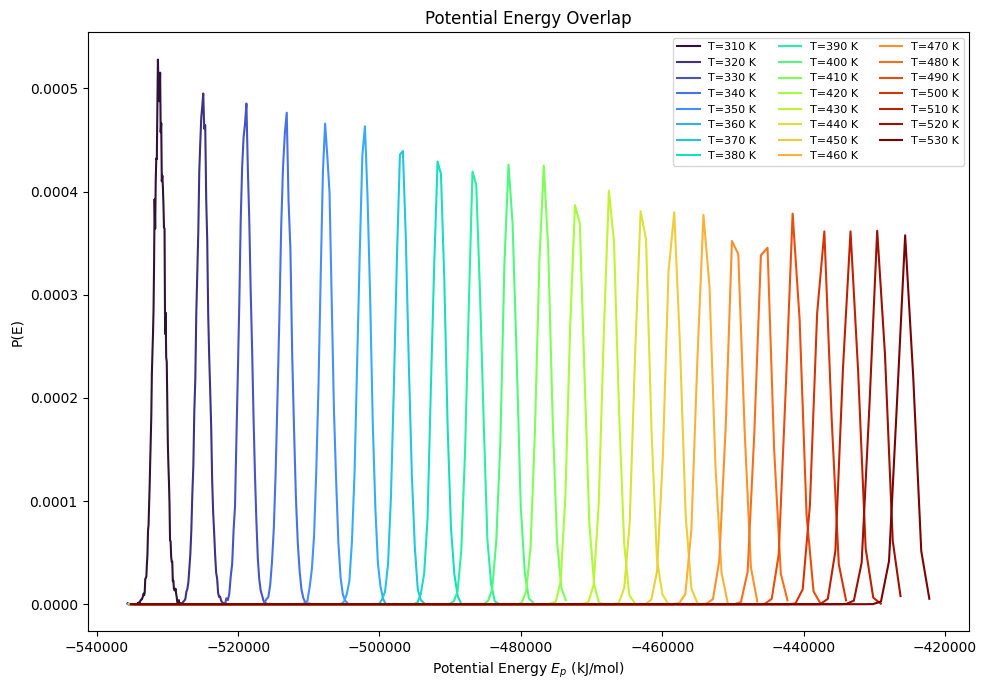

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Plot Potential Energy Overlap
#   Input:  1b/TXXX/potential.xvg
# ============================================================

main_dir = "1b"
Ts = list(range(310, 531, 10))

cmap = plt.cm.turbo
colors = cmap(np.linspace(0, 1, len(Ts)))

plt.figure(figsize=(10, 7))

for i, T in enumerate(Ts):

    pot_file = os.path.join(main_dir, f"T{T}", "potential.xvg")

    if not os.path.exists(pot_file):
        print(f"❌ Missing: {pot_file}")
        continue

    data = np.loadtxt(pot_file)

    if data.ndim == 1:
        continue

    time = data[:, 0]
    pot = data[:, 1]

    pdf, edges = np.histogram(
        pot,
        bins=100,
        density=True
    )

    bin_centers = 0.5 * (edges[:-1] + edges[1:])

    plt.plot(
        bin_centers,
        pdf,
        color=colors[i],
        lw=1.5,
        label=f"T={T} K"
    )

plt.xlabel(r"Potential Energy $E_p$ (kJ/mol)")
plt.ylabel("P(E)")
plt.title("Potential Energy Overlap")
plt.legend(fontsize=8, ncol=3)
plt.tight_layout()
plt.show()

Inference 🔍

Potential energy distributions shift progressively toward higher energies with increasing temperature, consistent with greater thermal excitation of the protein system.

✨ Neighboring temperature windows show reasonable overlap, suggesting the **310–530 K ladder** provides continuous thermodynamic coverage suitable for refining the transition region and guiding subsequent enhanced sampling setup.

Additional: Notice that the energy distributions are smaller than 3PRG & 6ONJ indicating that we need to move uptil 600 (in other words we need more energy to unfold as much as 3PRG or 6ONJ)

# We have reached the END of Part1 please proceed to 2_6ONI_HREMD.ipynb